# 1. Preparation


## 1.1. Importing Libs and Blah Blah ...


In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import math

In [2]:
%matplotlib inline
warnings.filterwarnings('ignore')

## 1.2. Defining Init Population Function


In [3]:
def initialize_population(num_individuals, num_variables):
    pop = np.random.randint(2, size=(num_individuals, num_variables))

    return pop

In [4]:
np.random.seed(42)
pop = initialize_population(8, 5)
print(pop)

[[0 1 0 0 0]
 [1 0 0 0 1]
 [0 0 0 0 1]
 [0 1 1 1 0]
 [1 0 1 1 1]
 [1 1 1 1 1]
 [0 0 1 1 1]
 [0 1 0 0 0]]


## 1.2. Defining Benchmark Functions


In [5]:
def one_max(ind):
    value = np.sum(ind)
    return value

In [6]:
def leading_one(ind):
    value = 0
    for bit in ind:
        if not bit:
            break
        value += 1

    return value

In [7]:
def concat_trap(ind, k=5):
    value = 0
    for i in range(0, len(ind), k):
        block = ind[i : i + k]
        block_sum = np.sum(block)
        value += block_sum if block_sum == k else k - 1 - block_sum

    return value

In [8]:
print(one_max(pop[0, :]))
print(leading_one(pop[0, :]))
print(concat_trap(pop[0, :]))

1
0
3


## 1.3. Defining Selection Functions


In [9]:
def truncation_selection(pop_fitness, selection_size):
    selected_indices = np.argsort(pop_fitness)[-selection_size:]
    return selected_indices

In [10]:
def proportional_selection(pop_fitness, selection_size):
    selection_prob = pop_fitness / np.sum(pop_fitness)
    selected_indices = np.random.choice(
        len(pop_fitness), size=selection_size, p=selection_prob, replace=True
    )
    return selected_indices

In [11]:
def tournament_selection(pop_fitness, selection_size, tournament_size=4):
    pop_size = len(pop_fitness)
    assert tournament_size <= pop_size, "Tournament size cannot exceed population size."

    selected_indices = []

    tournaments_per_shuffle = pop_size // tournament_size
    num_iter = math.ceil(selection_size / tournaments_per_shuffle)

    for _ in range(num_iter):
        random_indices = np.random.permutation(pop_size)

        for i in range(0, tournaments_per_shuffle * tournament_size, tournament_size):
            tournament_indices = random_indices[i : i + tournament_size]

            winner_idx = tournament_indices[np.argmax(pop_fitness[tournament_indices])]
            selected_indices.append(winner_idx)

            # early stopping
            if len(selected_indices) == selection_size:
                return np.array(selected_indices)

    return np.array(selected_indices[:selection_size])

## 1.4. Defining Crossover & Mutation Functions


In [12]:
def crossover(pop, crossover_rate: float = 0.5):
    num_individuals = len(pop)
    num_parameters = len(pop[0])
    indices = np.arange(num_individuals)
    # Đảo ngẫu nhiên thứ tự các cá thể trong quần thể
    np.random.shuffle(indices)
    offspring = []

    for i in range(0, num_individuals, 2):
        idx1 = indices[i]
        idx2 = indices[i + 1]
        offspring1 = list(pop[idx1])
        offspring2 = list(pop[idx2])

        # Cài đặt phép lai đồng nhất uniform crossover.
        for idx in range(0, num_parameters):
            r = np.random.rand()
            if r < crossover_rate:
                temp = offspring2[idx]
                offspring2[idx] = offspring1[idx]
                offspring1[idx] = temp

        offspring.append(offspring1)
        offspring.append(offspring2)

    offspring = np.array(offspring)
    return offspring

In [13]:
def mutation(pop, mutation_prob):
    num_individuals = len(pop)
    num_parameters = len(pop[0])
    for i in range(0, num_individuals):
        for j in range(0, num_parameters):
            r = np.random.rand()
            if r < mutation_prob:
                if pop[i][j] == 0:
                    pop[i][j] = 1
                else:
                    pop[i][j] = 0

    return pop

# 2. Genetic Algorithm with POPOP Implementation


## 2.1. Defining the Main Loop of the Algorithm


In [14]:
STUDENT_ID = 23520199
N_TRIALS = 10
MAX_EVALUATIONS = 10000

### 2.1.1. GA Function


In [15]:
def genetic_algorithm(
    num_individuals,
    num_parameters,
    objective,
    selection_method,
    max_evaluations,
    verbose=False,
):
    pop = initialize_population(num_individuals, num_parameters)
    pop_fitness = np.array([objective(ind) for ind in pop])
    num_evaluations = num_individuals
    best_fitness = []
    if verbose:
        print("#Gen 0:")
        print(pop_fitness)

    selection_size = num_individuals

    while num_evaluations < max_evaluations:
        best_fitness.append([num_evaluations, np.max(pop_fitness)])

        offspring = crossover(pop)
        offspring_fitness = np.array([objective(ind) for ind in offspring])

        pop = np.vstack([pop, offspring])
        pop_fitness = np.concatenate((pop_fitness, offspring_fitness))

        num_evaluations += len(offspring)

        selected_indices = selection_method(pop_fitness, selection_size)
        pop = pop[selected_indices]
        pop_fitness = pop_fitness[selected_indices]

        if verbose:
            print(pop_fitness)

    best_fitness.append([num_evaluations, np.max(pop_fitness)])
    if verbose:
        print("#Final result:")
        print(pop)
        print(pop_fitness)

    return (pop, pop_fitness, best_fitness)

### 2.1.2. Helper Function


In [16]:
# Helper function to run the genetic algorithm and plot results, avoiding code duplication in the notebook.
def run_and_plot(
    num_individuals,
    num_parameters,
    objective_name,
    selection_method_name,
    max_evaluations,
    color="blue",
):
    fits = []
    evals = []

    if objective_name == "one_max":
        objective = one_max
    elif objective_name == "leading_one":
        objective = leading_one
    elif objective_name == "concat_trap":
        objective = concat_trap
    else:
        raise ValueError("Invalid objective function name.")

    if selection_method_name == "truncation":
        selection_method = truncation_selection
    elif selection_method_name == "proportional":
        selection_method = proportional_selection
    elif selection_method_name == "tournament":
        selection_method = tournament_selection
    else:
        raise ValueError("Invalid selection method name.")

    for i in range(N_TRIALS):

        # Set a different random seed = STUDENT_ID + 0 -> STUDENT_ID + N_TRIALS - 1
        np.random.seed(STUDENT_ID + i)

        _, _, best_fitness = genetic_algorithm(
            num_individuals,
            num_parameters,
            objective,
            selection_method,
            max_evaluations,
        )

        best_fitness = np.array(best_fitness)
        if i == 0:
            evals = best_fitness[:, 0]

        fits.append(best_fitness[:, 1])

    fits = np.array(fits)
    avg = np.mean(fits, axis=0)
    err = np.std(fits, axis=0)

    plt.figure(figsize=(12, 6))
    plt.plot(evals, avg, label=selection_method_name.capitalize(), color=color)
    plt.fill_between(evals, avg - err, avg + err, alpha=0.2, color=color)
    plt.xlabel("Number of Evaluations")
    plt.ylabel("Fitness")
    plt.title(
        f"{objective_name.replace('_', ' ').title()} with {num_parameters} Dimensions"
    )
    plt.legend()
    plt.grid()
    plt.show()

    return evals, avg, err

## 2.2. Experimenting with OneMax Function (100 bits)


In [17]:
num_individuals = 128
num_parameters = 100

### 2.2.1. With Truncation Selection


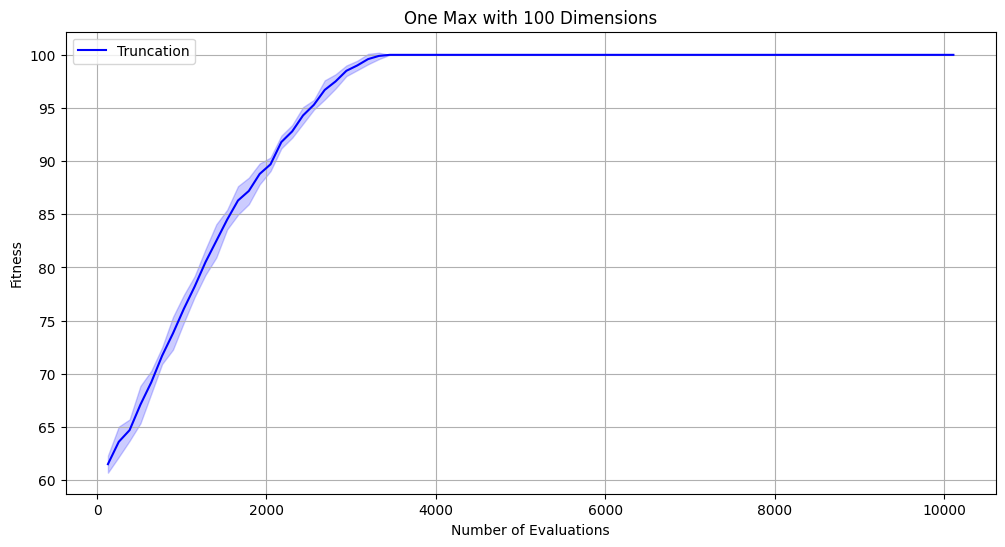

In [18]:
evals, truncation_avg, truncation_err = run_and_plot(
    num_individuals,
    num_parameters,
    "one_max",
    "truncation",
    MAX_EVALUATIONS,
)

### 2.2.2. With Proportional Selection


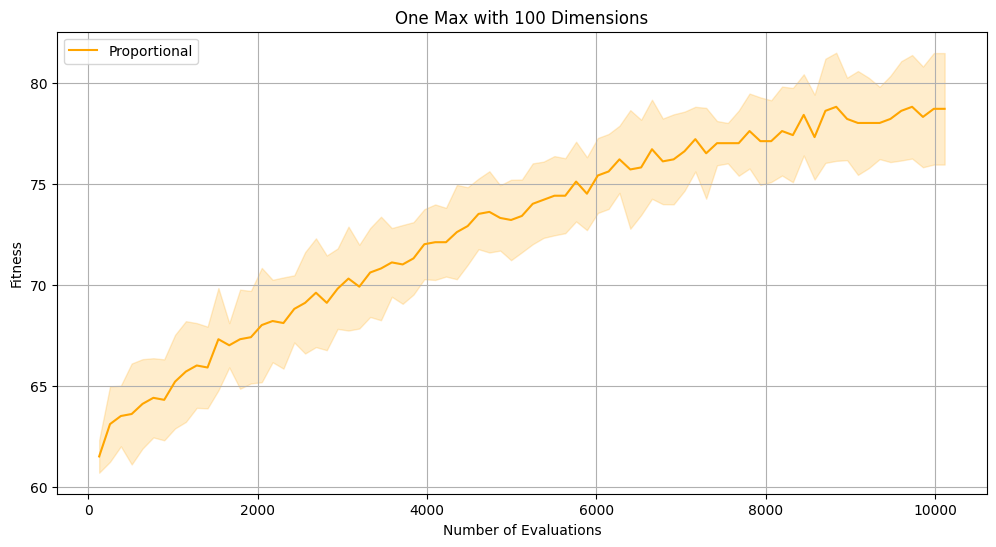

In [19]:
_, proportional_avg, proportional_err = run_and_plot(
    num_individuals,
    num_parameters,
    "one_max",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

### 2.2.3. With Tournament Selection


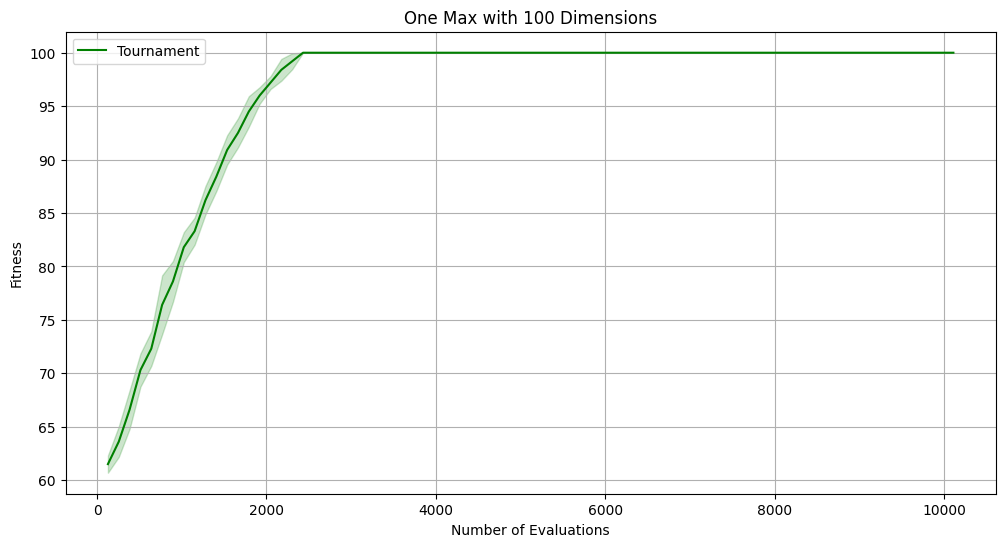

In [20]:
_, tournament_avg, tournament_err = run_and_plot(
    num_individuals,
    num_parameters,
    "one_max",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

### 2.2.4. Comparison of the Three Selection Methods


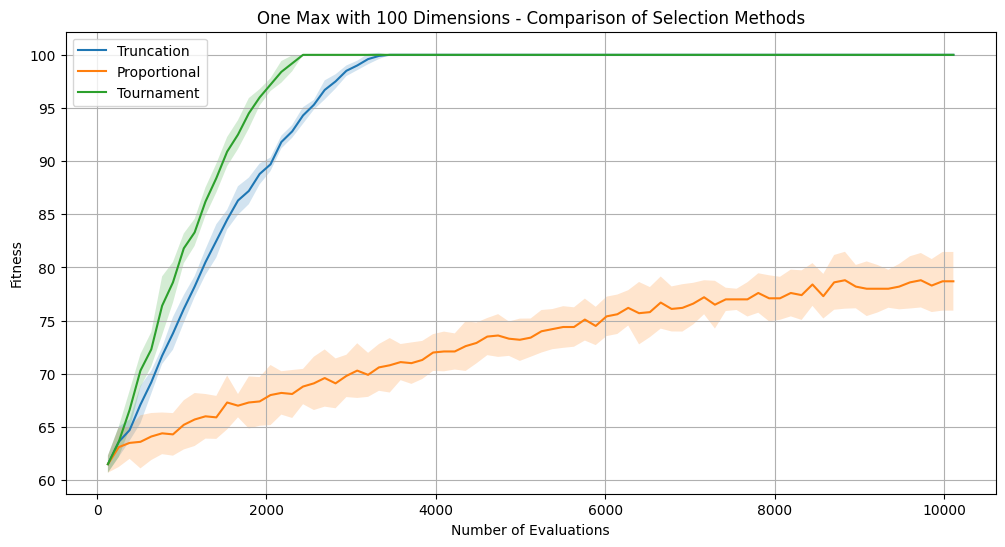

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(evals, truncation_avg, label="Truncation")
plt.fill_between(
    evals, truncation_avg - truncation_err, truncation_avg + truncation_err, alpha=0.2
)
plt.plot(evals, proportional_avg, label="Proportional")
plt.fill_between(
    evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(evals, tournament_avg, label="Tournament")
plt.fill_between(
    evals, tournament_avg - tournament_err, tournament_avg + tournament_err, alpha=0.2
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(f"One Max with {num_parameters} Dimensions - Comparison of Selection Methods")
plt.legend()
plt.grid()
plt.show()

In [22]:
print("Truncation: ", truncation_avg[-1], "±", truncation_err[-1])
print("Proportional: ", proportional_avg[-1], "±", proportional_err[-1])
print("Tournament: ", tournament_avg[-1], "±", tournament_err[-1])

Truncation:  100.0 ± 0.0
Proportional:  78.7 ± 2.758622844826744
Tournament:  100.0 ± 0.0


## 2.3. Experimenting with LeadingOne Function (20 bits)


In [23]:
num_individuals = 128
num_parameters = 20

### 2.3.1. With Truncation Selection


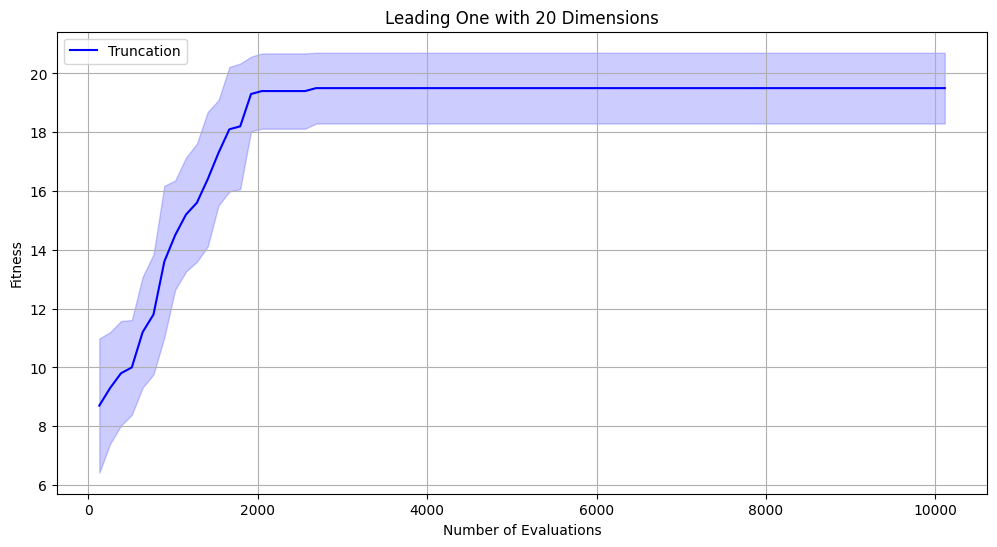

In [24]:
evals, truncation_avg, truncation_err = run_and_plot(
    num_individuals,
    num_parameters,
    "leading_one",
    "truncation",
    MAX_EVALUATIONS,
)

### 2.3.2. With Proportional Selection


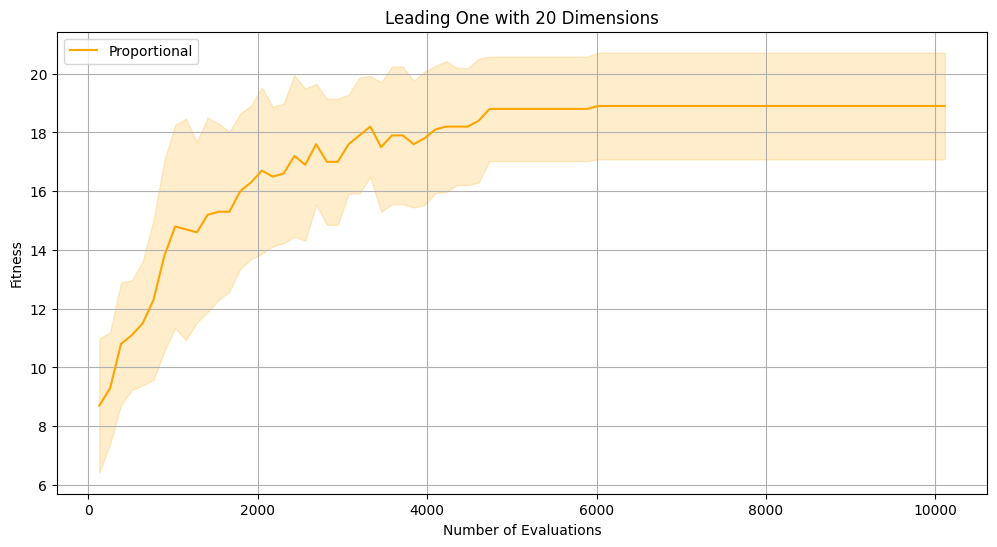

In [25]:
_, proportional_avg, proportional_err = run_and_plot(
    num_individuals,
    num_parameters,
    "leading_one",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

### 2.3.3. With Tournament Selection


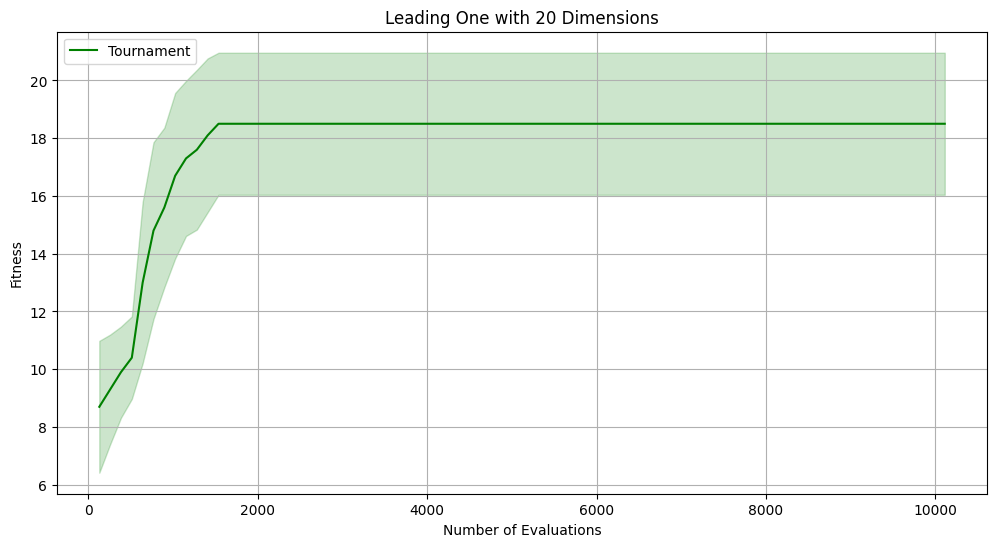

In [26]:
_, tournament_avg, tournament_err = run_and_plot(
    num_individuals,
    num_parameters,
    "leading_one",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

### 2.3.4. Comparison of the Three Selection Methods


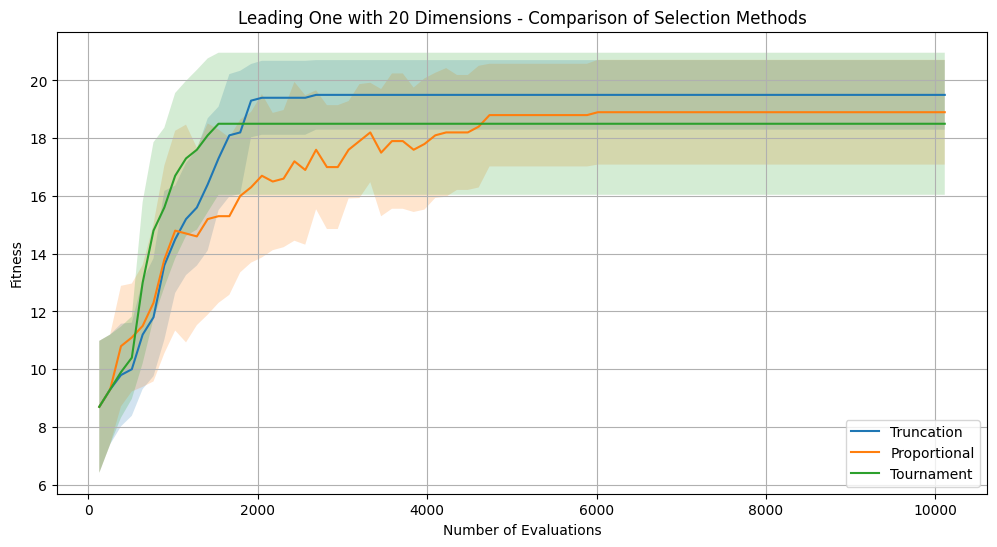

In [27]:
plt.figure(figsize=(12, 6))
plt.plot(evals, truncation_avg, label="Truncation")
plt.fill_between(
    evals, truncation_avg - truncation_err, truncation_avg + truncation_err, alpha=0.2
)
plt.plot(evals, proportional_avg, label="Proportional")
plt.fill_between(
    evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(evals, tournament_avg, label="Tournament")
plt.fill_between(
    evals, tournament_avg - tournament_err, tournament_avg + tournament_err, alpha=0.2
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(
    f"Leading One with {num_parameters} Dimensions - Comparison of Selection Methods"
)
plt.legend()
plt.grid()
plt.show()

In [28]:
print("Truncation: ", truncation_avg[-1], "±", truncation_err[-1])
print("Proportional: ", proportional_avg[-1], "±", proportional_err[-1])
print("Tournament: ", tournament_avg[-1], "±", tournament_err[-1])

Truncation:  19.5 ± 1.2041594578792296
Proportional:  18.9 ± 1.8138357147217055
Tournament:  18.5 ± 2.4596747752497685


## 2.4. Experimenting with Concatenated Trap-5 Function (25 bits)


In [29]:
num_individuals = 128
num_parameters = 25

### 2.4.1. With Truncation Selection


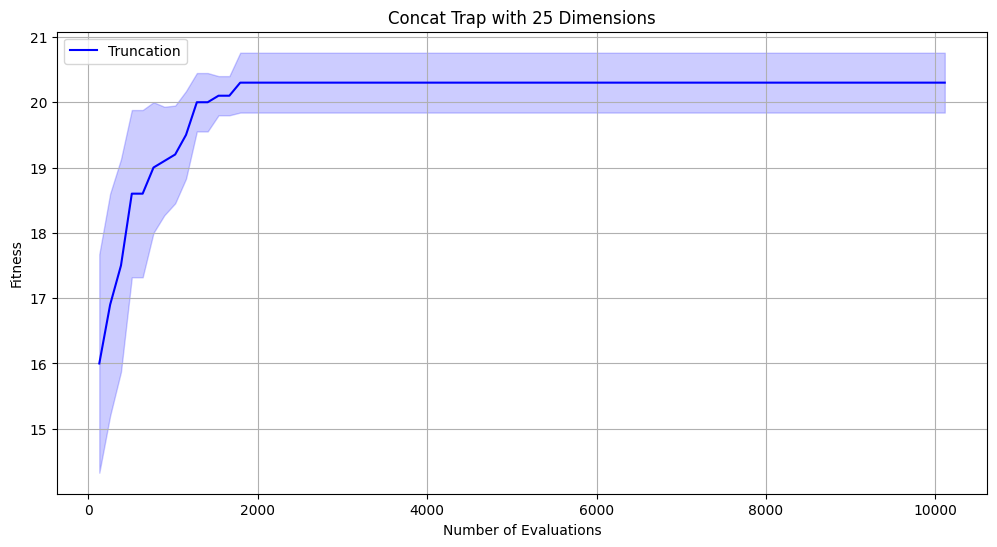

In [30]:
evals, truncation_avg, truncation_err = run_and_plot(
    num_individuals,
    num_parameters,
    "concat_trap",
    "truncation",
    MAX_EVALUATIONS,
)

### 2.4.2. With Proportional Selection


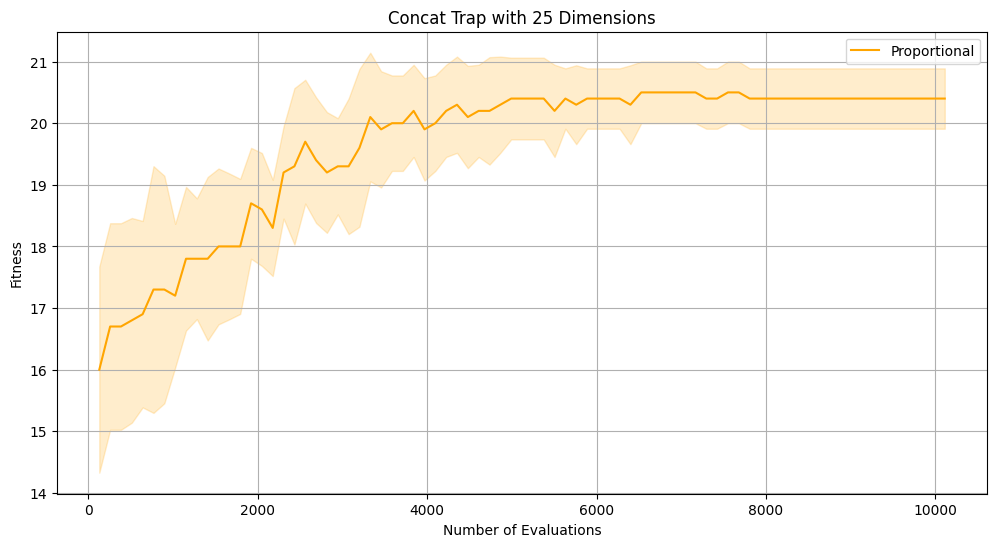

In [31]:
_, proportional_avg, proportional_err = run_and_plot(
    num_individuals,
    num_parameters,
    "concat_trap",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

### 2.4.3. With Tournament Selection


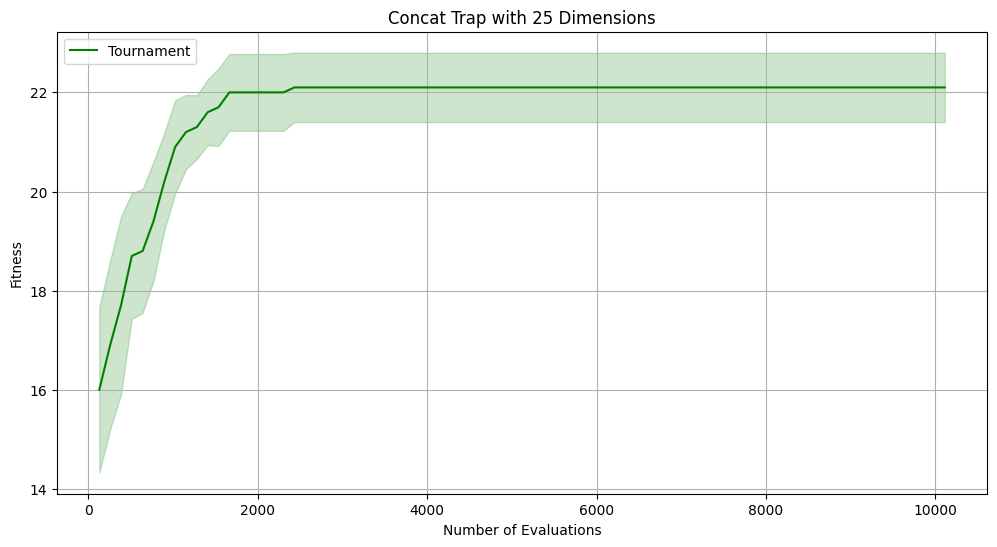

In [32]:
_, tournament_avg, tournament_err = run_and_plot(
    num_individuals,
    num_parameters,
    "concat_trap",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

### 2.4.4. Comparison of the Three Selection Methods


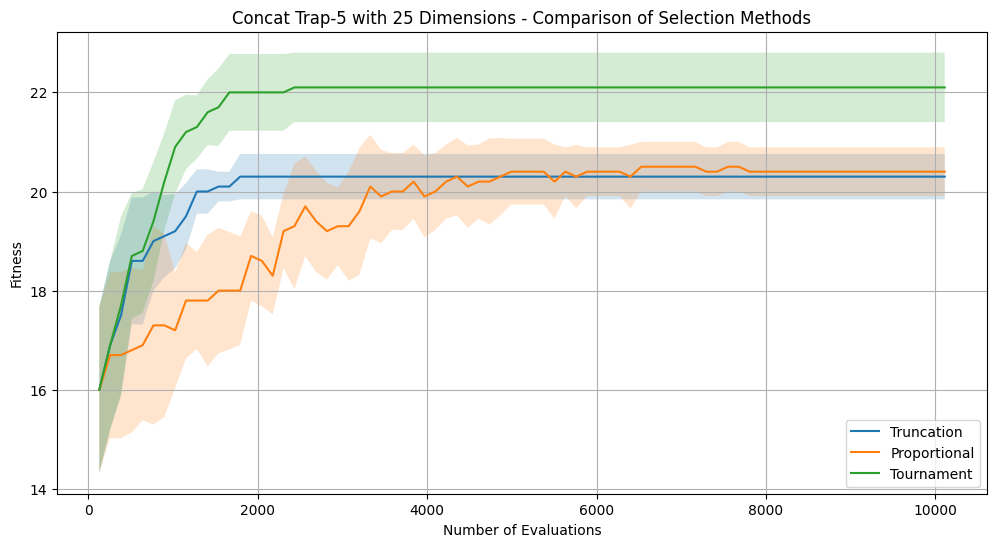

In [33]:
plt.figure(figsize=(12, 6))
plt.plot(evals, truncation_avg, label="Truncation")
plt.fill_between(
    evals, truncation_avg - truncation_err, truncation_avg + truncation_err, alpha=0.2
)
plt.plot(evals, proportional_avg, label="Proportional")
plt.fill_between(
    evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(evals, tournament_avg, label="Tournament")
plt.fill_between(
    evals, tournament_avg - tournament_err, tournament_avg + tournament_err, alpha=0.2
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(
    f"Concat Trap-5 with {num_parameters} Dimensions - Comparison of Selection Methods"
)
plt.legend()
plt.grid()
plt.show()

In [34]:
print("Truncation: ", truncation_avg[-1], "±", truncation_err[-1])
print("Proportional: ", proportional_avg[-1], "±", proportional_err[-1])
print("Tournament: ", tournament_avg[-1], "±", tournament_err[-1])

Truncation:  20.3 ± 0.45825756949558394
Proportional:  20.4 ± 0.4898979485566356
Tournament:  22.1 ± 0.7000000000000001


# 3. Thoughts and Conclusion


### Performance Analysis

**1. Overall Performance**

There is no single selection method that consistently outperforms the others across all benchmark functions. The effectiveness of each selection method depends heavily on the specific characteristics and fitness landscape of the problem being optimized (which aligns with the "No Free Lunch" theorem in optimization).

**2. Breakdown by Benchmark Function**

- **One Max (100 Dimensions):** **Truncation Selection** and **Tournament Selection** performed the best, converging at the maximum fitness (100) with low variance. Notably, **Tournament Selection** showed a slightly faster initial convergence rate compared to Truncation. Conversely, **Proportional Selection** performed the worst, suffering from a much slower convergence rate, high variance, and failing to reach the optimal fitness within the evaluation limit (plateauing around 80).
- **Leading One (20 Dimensions):** **Truncation Selection** achieved the best overall performance, reaching the highest final average fitness level (19.5). **Tournament Selection** converged the fastest initially but suffered from premature convergence, plateauing at a lower local optimum (18.5). **Proportional Selection** started very slowly but maintained a steady climb, eventually surpassing Tournament selection in the later evaluations.
- **Concat Trap-5 (25 Dimensions):** **Tournament Selection** was the clear winner here, successfully navigating the deceptive nature of the problem to reach the highest average fitness (22.1) with fast convergence. Both **Truncation** and **Proportional** selections performed worse, getting trapped at lower sub-optimal levels (20.3 and 20.4), indicating they struggled to maintain the necessary diversity to escape local optima.

---

### Conclusion

**Which method gives the best results?**
If we must choose an overall winner based on these specific charts, **Tournament Selection** is arguably the most robust choice. It dominated the deceptive Trap-5 function and performed exceptionally well (tied for first) on the simple One Max function. While it fell slightly behind Truncation on Leading One, its ability to avoid worst-case scenarios across varying problem types makes it highly reliable. **Truncation** is a close second, excelling in simpler, non-deceptive landscapes but faltering when faced with "traps."

**Why do they behave this way?**

- **Proportional Selection** clearly struggles due to a loss of **selection pressure**. As the population improves and fitness values become closer to one another, the probability of selecting the best individuals over average ones diminishes drastically. This causes the algorithm to stall, as seen vividly in the One Max graph.
- **Truncation Selection** applies very high selection pressure by strictly taking the top percentage of the population. This leads to excellent and rapid results in smooth, unimodal landscapes (One Max, Leading One). However, this greedy approach rapidly destroys genetic diversity, making it highly susceptible to getting stuck in local optima on deceptive landscapes (Trap-5).
- **Tournament Selection** provides an excellent balance. By adjusting the tournament size, it maintains enough selection pressure to converge quickly (seen in One Max), while still preserving enough genetic diversity to escape deceptive traps better than Truncation (seen in Trap-5).
